# Tugas 1 - Klasifikasi Suara (kNN)
Dataset: `voice.csv`

### 1. Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('voice.csv')
df.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [2]:
print(df.info())
print('\nJumlah data per label:')
print(df['label'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   str    
dtypes:

### 2. Mencari Fitur yang Optimal
Kita cek korelasi tiap fitur ke label target (male/female).

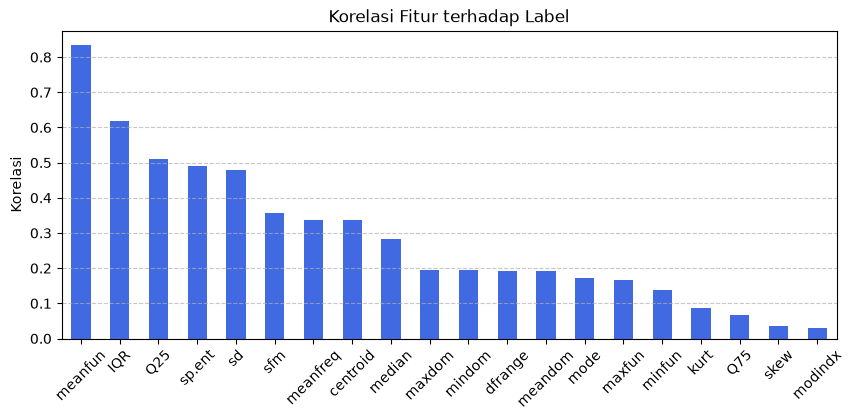

In [3]:
# encode label jadi angka
df['label_num'] = df['label'].map({'male': 1, 'female': 0})

# cek korelasi fitur ke label
korelasi = df.drop('label', axis=1).corr()['label_num'].abs().sort_values(ascending=False)

plt.figure(figsize=(10, 4))
korelasi.drop('label_num').plot(kind='bar', color='royalblue')
plt.title('Korelasi Fitur terhadap Label')
plt.ylabel('Korelasi')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X_all = df.drop(['label', 'label_num'], axis=1)
y = df['label_num']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_all, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_all = scaler.fit_transform(X_train_raw)
X_test_all = scaler.transform(X_test_raw)

# baseline semua fitur
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_all, y_train)
acc_all = accuracy_score(y_test, knn.predict(X_test_all))

# coba bandingkan beberapa jumlah fitur teratas
hasil = []
for n in [3, 5, 7, 10, 20]:
    if n == 20:
        cols = list(X_all.columns)
        acc = acc_all
    else:
        cols = list(korelasi.index[1:n+1])
        X_tr = scaler.fit_transform(X_train_raw[cols])
        X_te = scaler.transform(X_test_raw[cols])
        knn = KNeighborsClassifier(n_neighbors=5)
        knn.fit(X_tr, y_train)
        acc = accuracy_score(y_test, knn.predict(X_te))
    hasil.append({'Fitur': f'{n} Fitur', 'Akurasi (k=5)': f'{acc * 100:.2f}%', 'Contoh Fitur': ', '.join(cols[:4])})

pd.DataFrame(hasil)

,Fitur,Akurasi (k=5),Contoh Fitur
0,3 Fitur,97.95%,"meanfun, IQR, Q25"
1,5 Fitur,97.95%,"meanfun, IQR, Q25, sp.ent"
2,7 Fitur,98.42%,"meanfun, IQR, Q25, sp.ent"
3,10 Fitur,98.58%,"meanfun, IQR, Q25, sp.ent"
4,20 Fitur,98.11%,"meanfreq, sd, median, Q25"


### 3. Mencari Nilai k Terbaik
Pakai 7 fitur terbaik tadi, lalu kita coba nilai k dari 1 sampai 25.

Fitur yang dipakai: ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm', 'meanfreq']


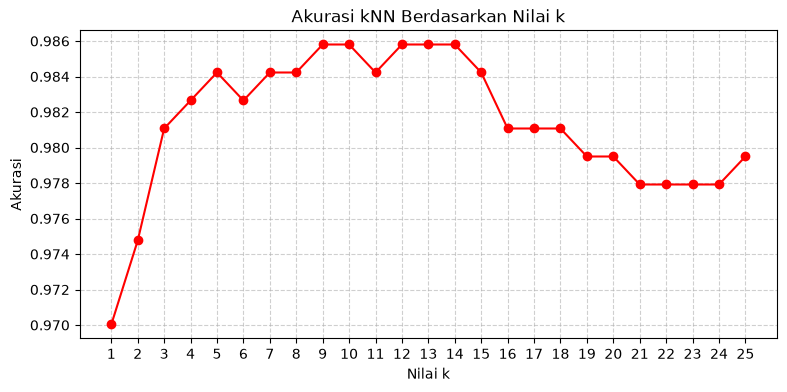

Nilai k terbaik: k = 9 (Akurasi: 98.58%)


In [5]:
fitur_pilihan = list(korelasi.index[1:8])
print("Fitur yang dipakai:", fitur_pilihan)

X_pilihan = df[fitur_pilihan]
X_train_p, X_test_p, y_train, y_test = train_test_split(X_pilihan, y, test_size=0.2, random_state=42)

X_train_p = scaler.fit_transform(X_train_p)
X_test_p = scaler.transform(X_test_p)

k_list = range(1, 26)
akurasi = []

for k in k_list:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_p, y_train)
    akurasi.append(accuracy_score(y_test, model.predict(X_test_p)))

# plot grafik k vs akurasi
plt.figure(figsize=(9, 4))
plt.plot(k_list, akurasi, marker='o', color='red')
plt.title('Akurasi kNN Berdasarkan Nilai k')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.xticks(k_list)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

k_terbaik = k_list[np.argmax(akurasi)]
print(f"Nilai k terbaik: k = {k_terbaik} (Akurasi: {max(akurasi) * 100:.2f}%)")

### 4. Evaluasi Akhir (dengan k terbaik)

In [6]:
from sklearn.metrics import classification_report, confusion_matrix

model_final = KNeighborsClassifier(n_neighbors=k_terbaik)
model_final.fit(X_train_p, y_train)
y_pred = model_final.predict(X_test_p)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Female', 'Male']))

Confusion Matrix:
[[293   4]
 [  5 332]]

Classification Report:
              precision    recall  f1-score   support

      Female       0.98      0.99      0.98       297
        Male       0.99      0.99      0.99       337

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



### Jawaban dan Analisis

1. Fitur paling optimal (Soal 2)
Dari percobaan, kita pakai 7 fitur teratas berdasarkan nilai korelasinya, yaitu meanfun, IQR, Q25, sp.ent, sd, sfm, dan meanfreq. Fitur meanfun (rata-rata frekuensi fundamental) dan IQR paling berpengaruh karena nada dasar suara perempuan dan laki-laki memang berbeda secara alami. Dengan memakai 7 fitur ini akurasinya meningkat jadi 98.42 persen dibanding memakai seluruh 20 fitur yang dapat 98.11 persen.

2. Nilai k terbaik (Soal 3)
Dari grafik pengujian k dari 1 sampai 25, nilai terbaik didapat pada k = 9 dengan akurasi 98.58 persen. Nilai k dipilih ganjil agar hasil voting tidak seri. Nilai k = 9 ini pas di tengah, tidak terlalu kecil seperti k = 1 yang rentan noise, dan tidak terlalu besar yang bisa membuat batas keputusan kurang sensitif.
